# Pjesa I · 2/2: Pastrimi dhe përgatitja për analizë

**Qëllimi:** të përgatisim një tabelë për analizën e çmimit për natë. Çdo hap më poshtë shpjegon vendimin, kontrollon rezultatin dhe krijon grafikë. Dataset-i origjinal nuk ndryshohet; rezultati ruhet te `dataset/listings_preprocessed.csv`.

Ekzekutoni së pari notebook-un 01 për të parë problemet fillestare. Ky notebook mund të ekzekutohet edhe më vete nga rrënja e projektit.

In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path(os.environ.get("PVDH_PROJECT_ROOT", Path.cwd()))
if not (ROOT / "dataset" / "listings.csv.gz").is_file() and (ROOT.parent / "dataset" / "listings.csv.gz").is_file():
    ROOT = ROOT.parent
DATA_PATH = Path(os.environ.get("PVDH_DATASET_PATH", ROOT / "dataset" / "listings.csv.gz"))
raw = pd.read_csv(DATA_PATH, low_memory=False, dtype={"host_profile_id": "string"})
df = raw.copy()
log = []
def record(step):
    log.append({"hapi": step, "rreshta": len(df), "kolona": df.shape[1], "qeliza boshe": int(df.isna().sum().sum())})
record("Fillimi")
print(f"Fillimi: {len(df):,} rreshta × {df.shape[1]} kolona")

Fillimi: 91,954 rreshta × 90 kolona


## 1. Pastrimi bazë dhe tipet

Heqim kolonat 100% boshe dhe ID-të e përsëritura, por ruajmë `bathrooms`: megjithëse është bosh në këtë version, mund ta rindërtojmë nga `bathrooms_text`. Kthejmë `price` në numër duke larguar formatimin (`$`, presje). Datat ruhen si `datetime`, ndërsa `t/f` bëhet `True/False` pa e ngatërruar mungesën me `False`.

In [2]:
empty_columns = [col for col in df.columns[df.isna().all()] if col != "bathrooms"]
df = df.drop(columns=empty_columns).drop_duplicates(subset="id", keep="first").copy()
df["price"] = pd.to_numeric(df["price"].astype("string").str.replace(r"[$,]", "", regex=True), errors="coerce")
for col in ["last_scraped", "calendar_last_scraped", "first_review", "last_review"]:
    if col in df:
        df[col] = pd.to_datetime(df[col], errors="coerce")
boolean_columns = ["host_is_superhost", "host_has_profile_pic", "host_identity_verified", "has_availability"]
for col in boolean_columns:
    if col in df:
        df[col] = df[col].map({"t": True, "f": False}).astype("boolean")
record("Kolona boshe, ID, tipe")
print(f"Kolona 100% boshe të hequra: {len(empty_columns)}: {', '.join(empty_columns)}")
print(f"ID të dyfishuara të hequra: {len(raw) - len(df)}")
display(df[["price", "last_scraped", "host_is_superhost"]].dtypes.to_frame("tipi i korrigjuar"))

Kolona 100% boshe të hequra: 14: neighborhood_overview, host_since, host_response_time, host_response_rate, host_acceptance_rate, host_thumbnail_url, host_neighbourhood, host_total_listings_count, host_verifications, neighbourhood, neighbourhood_group_cleansed, calendar_updated, license, instant_bookable
ID të dyfishuara të hequra: 0


,tipi i korrigjuar
price,Float64
last_scraped,datetime64[ns]
host_is_superhost,boolean


## 2. Trajtimi i mungesave

`price` është variabla që duam të analizojmë. Nuk e plotësojmë me mesatare, sepse kjo do të krijonte çmime të sajuara; heqim rreshtat pa çmim. `bathrooms` merret fillimisht nga `bathrooms_text` (p.sh. *1.5 baths*). Për `bathrooms`, `bedrooms` dhe `beds`, mungesat e mbetura plotësohen me medianën e listimeve me të njëjtin `accommodates`, pastaj me medianën e përgjithshme. Kjo është supozim praktik dhe duhet përmendur si kufizim.

Mungesat në rezultatet e komenteve ruhen: listimi pa komente nuk ka vlerësim. `reviews_per_month` bëhet 0 vetëm kur `number_of_reviews == 0`.

In [3]:
missing_price = int(df["price"].isna().sum())
df = df.dropna(subset=["price"]).copy()
bad_price = int(df["price"].le(0).sum())
df = df[df["price"].gt(0)].copy()
record("Heqja e çmimit të munguar/jo pozitiv")
print(f"Pa çmim: {missing_price:,}; çmim <= 0: {bad_price:,}")

if "bathrooms" in df and "bathrooms_text" in df:
    bath_text = df["bathrooms_text"].astype("string")
    parsed = pd.to_numeric(bath_text.str.extract(r"(\d+(?:\.\d+)?)")[0], errors="coerce")
    parsed = parsed.mask(parsed.isna() & bath_text.str.contains("half", case=False, na=False), 0.5)
    df["bathrooms"] = df["bathrooms"].fillna(parsed)

imputations = {}
for col in ["bathrooms", "bedrooms", "beds"]:
    before = int(df[col].isna().sum())
    group_median = df.groupby("accommodates")[col].transform("median")
    df[col] = df[col].fillna(group_median).fillna(df[col].median())
    imputations[col] = before - int(df[col].isna().sum())
no_reviews = df["number_of_reviews"].eq(0)
df.loc[no_reviews & df["reviews_per_month"].isna(), "reviews_per_month"] = 0
record("Plotësimi i zgjedhur i mungesave")
display(pd.Series(imputations, name="vlera të plotësuara").to_frame())

Pa çmim: 32,049; çmim <= 0: 0


,vlera të plotësuara
bathrooms,98
bedrooms,24
beds,1502


## 3. Vlerat ekstreme

Çmimet shumë të larta mund të jenë gabime ose listime luksoze. I shënojmë me kufirin e percentilit 99, por **nuk i fshijmë nga dataset-i**. Grafiku i shpërndarjes përdor vetëm vlerat deri në këtë kufi që pjesa kryesore e të dhënave të lexohet qartë; tabela ruan të gjitha çmimet pozitive.

P99: 1272.16; listime mbi kufi: 600


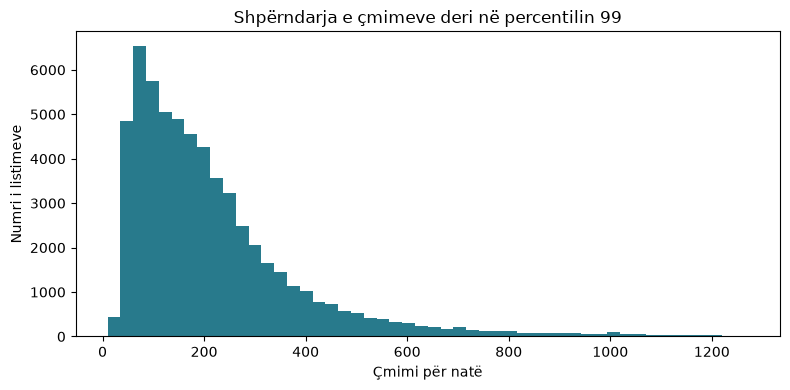

In [4]:
price_p99 = df["price"].quantile(0.99)
df["price_above_p99"] = df["price"].gt(price_p99)
print(f"P99: {price_p99:.2f}; listime mbi kufi: {int(df['price_above_p99'].sum()):,}")
ax = df.loc[~df["price_above_p99"], "price"].plot.hist(bins=50, figsize=(8, 4), color="#287a8c")
ax.set(xlabel="Çmimi për natë", ylabel="Numri i listimeve", title="Shpërndarja e çmimeve deri në percentilin 99")
plt.tight_layout()
plt.show()
record("Shënimi i çmimeve ekstreme")

## 4. Krijimi i vetive, binarizimi dhe diskretizimi

`has_reviews` dhe `is_superhost` janë veti binare. `price_band` e ndan çmimin në tri grupe sipas tercileve të këtij dataset-i. Nëse çmimi përdoret si variabël që parashikohet, **mos përdorni `price_band` si hyrje të modelit**: ajo është krijuar nga vetë çmimi.

In [5]:
df["has_reviews"] = df["number_of_reviews"].gt(0)
df["is_superhost"] = df["host_is_superhost"].astype("boolean")
df["price_band"] = pd.qcut(df["price"], q=3, labels=["i ulët", "mesatar", "i lartë"], duplicates="drop")
df["amenity_count"] = df["amenities"].fillna("[]").astype(str).str.count('"') // 2
record("Vetitë e reja dhe kategoritë")
display(df[["price", "price_band", "has_reviews", "is_superhost", "amenity_count"]].head())

,price,price_band,has_reviews,is_superhost,amenity_count
0,267.5,i lartë,True,False,43
1,127.0,mesatar,True,True,44
2,137.5,mesatar,True,False,25
3,228.0,mesatar,True,False,68
5,290.0,i lartë,True,False,47


## 5. Zgjedhja e vetive dhe reduktimi i dimensionit

Për analizën e çmimit ruajmë një nënbashkësi të kuptueshme kolonash. ID-të, URL-të dhe teksti i gjatë nuk nevojiten si veti numerike në këtë fazë. `id` ruhet vetëm për gjurmim. Numri i kolonave bie edhe nga heqja e kolonave krejt bosh. PCA nuk përdoret këtu, sepse do të vështirësonte interpretimin e lagjes, llojit të dhomës dhe kapacitetit.

In [6]:
selected = ["id", "neighbourhood_cleansed", "room_type", "property_type", "accommodates", "bathrooms", "bedrooms", "beds", "price", "price_above_p99", "availability_365", "number_of_reviews", "reviews_per_month", "review_scores_rating", "has_reviews", "is_superhost", "amenity_count", "price_band"]
analysis = df[selected].copy()
print(f"Kolonat: {raw.shape[1]} fillestare → {df.shape[1]} pas pastrimit/krijimit → {analysis.shape[1]} për analizë")
display(analysis.head())

Kolonat: 90 fillestare → 81 pas pastrimit/krijimit → 18 për analizë


,id,neighbourhood_cleansed,room_type,property_type,accommodates,bathrooms,bedrooms,beds,price,price_above_p99,availability_365,number_of_reviews,reviews_per_month,review_scores_rating,has_reviews,is_superhost,amenity_count,price_band
0,11551,Lambeth,Entire home/apt,Entire rental unit,5,1.0,1.0,3.0,267.5,False,349,197,0.98,4.55,True,False,43,i lartë
1,13913,Islington,Private room,Private room in rental unit,1,1.0,1.0,1.0,127.0,False,350,57,0.29,4.86,True,True,44,mesatar
2,15400,Kensington and Chelsea,Entire home/apt,Entire rental unit,2,1.0,1.0,1.0,137.5,False,159,98,0.48,4.81,True,False,25,mesatar
3,24328,Wandsworth,Entire home/apt,Entire townhouse,2,1.5,1.0,1.0,228.0,False,272,97,0.50,4.90,True,False,68,mesatar
5,36299,Richmond upon Thames,Entire home/apt,Entire townhouse,5,1.5,3.0,3.0,290.0,False,350,117,0.60,4.80,True,False,47,i lartë


## 6. Transformimi dhe agregimi

Standardizojmë disa veti numerike si shembull për metoda që kërkojnë shkallë të ngjashme. Mesatarja dhe devijimi standard llogariten mbi dataset-in aktual; për një model parashikues, ato duhet të llogariten vetëm në **setin e trajnimit**. Kodojmë `room_type` me kolona 0/1. Për raportimin deskriptiv llogarisim medianën e çmimit sipas llojit të dhomës dhe lagjes.

Shembull i vetive të transformuara:


,accommodates_z,bathrooms_z,bedrooms_z,beds_z,availability_365_z,amenity_count_z,room_Entire home/apt,room_Hotel room,room_Private room,room_Shared room
0,0.633167,-0.481738,-0.547499,0.676127,1.056857,0.732079,1,0,0,0
1,-1.140397,-0.481738,-0.547499,-0.708912,1.065187,0.798521,0,0,1,0
2,-0.697006,-0.481738,-0.547499,-0.708912,-0.525943,-0.463879,1,0,0,0
3,-0.697006,0.200045,-0.547499,-0.708912,0.415406,2.393131,1,0,0,0
5,0.633167,0.200045,1.396198,0.676127,1.065187,0.997847,1,0,0,0


,count,median
room_type,,
Shared room,165,36.0
Private room,19085,80.0
Hotel room,134,187.5
Entire home/apt,40521,227.0


,count,median
neighbourhood_cleansed,,
Westminster,7960,282.0
Kensington and Chelsea,4652,273.18
Camden,4293,207.67
Tower Hamlets,3879,161.5
Southwark,3033,158.0
Lambeth,2837,153.2
Hackney,2828,164.46
Wandsworth,2694,185.21
Hammersmith and Fulham,2682,184.0


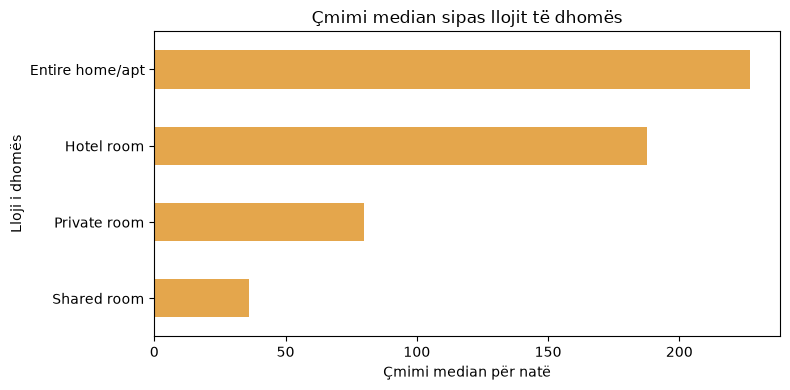

In [7]:
numeric_features = ["accommodates", "bathrooms", "bedrooms", "beds", "availability_365", "amenity_count"]
scaled = analysis[numeric_features].astype(float)
scaled = (scaled - scaled.mean()) / scaled.std(ddof=0).replace(0, 1)
scaled.columns = [f"{col}_z" for col in scaled]
encoded = pd.get_dummies(analysis["room_type"], prefix="room", dtype=int)
print("Shembull i vetive të transformuara:")
display(pd.concat([scaled, encoded], axis=1).head())

by_room = analysis.groupby("room_type")["price"].agg(["count", "median"]).sort_values("median")
by_area = analysis.groupby("neighbourhood_cleansed")["price"].agg(["count", "median"]).sort_values("count", ascending=False)
display(by_room.round(2))
display(by_area.head(10).round(2))
ax = by_room["median"].plot.barh(figsize=(8, 4), color="#e4a64c")
ax.set(xlabel="Çmimi median për natë", ylabel="Lloji i dhomës", title="Çmimi median sipas llojit të dhomës")
plt.tight_layout()
plt.show()

## 7. Kontrolli para/pas dhe ruajtja

Raporti tregon çfarë ndryshoi. Mungesat e mbetura te `review_scores_rating` janë të qëllimshme për listimet pa komente. Dataset-i final ruhet pa ndryshuar skedarin origjinal. Grafikët shfaqen brenda notebook-ut gjatë ekzekutimit dhe nuk ruhen si skedarë.

In [8]:
display(pd.DataFrame(log))
before = raw.isna().sum()
after = df.isna().sum().reindex(raw.columns, fill_value=0)
comparison = pd.DataFrame({"para": before, "pas": after}).sort_values("para", ascending=False)
display(comparison.head(25))
print(f"Rezultati për analizë: {len(analysis):,} rreshta × {analysis.shape[1]} kolona")
print(f"Vlerësime të mungura të ruajtura: {analysis['review_scores_rating'].isna().sum():,}")
output = ROOT / "dataset" / "listings_preprocessed.csv"
output.parent.mkdir(parents=True, exist_ok=True)
analysis.to_csv(output, index=False)
print(f"U ruajt: {output}")

,hapi,rreshta,kolona,qeliza boshe
0,Fillimi,91954,90,1933263
1,"Kolona boshe, ID, tipe",91954,76,645907
2,Heqja e çmimit të munguar/jo pozitiv,59905,76,289093
3,Plotësimi i zgjedhur i mungesave,59905,76,215404
4,Shënimi i çmimeve ekstreme,59905,77,215404
5,Vetitë e reja dhe kategoritë,59905,81,215404


,para,pas
neighborhood_overview,91954,0
host_since,91954,0
host_response_time,91954,0
host_thumbnail_url,91954,0
host_acceptance_rate,91954,0
host_response_rate,91954,0
host_verifications,91954,0
neighbourhood,91954,0
host_total_listings_count,91954,0
host_neighbourhood,91954,0


Rezultati për analizë: 59,905 rreshta × 18 kolona
Vlerësime të mungura të ruajtura: 12,258
U ruajt: C:\Users\Yllka\Desktop\FIEK\master\Viti 1\Sem 1\PVDH\Projektet\pvdh_group_10\dataset\listings_preprocessed.csv
